# Détection de caractéristiques

Détection de lignes sur la route (lane detection)

* https://www.geeksforgeeks.org/machine-learning/opencv-real-time-road-lane-detection/
  Canny + masque sur le trapèze devant l'image + hough


Détection de panneaux (Traffic Sign Detection)

* SIFT
* https://github.com/hoanglehaithanh/Traffic-Sign-Detection
* https://github.com/mohd-adeeb011/Traffic-Sign-Board-Recognition-Using-Camera

In [1]:
import skimage.io as io
import matplotlib.pyplot as plt
import skimage.color as clr
from skimage.feature import canny
import numpy as np
from skimage.transform import hough_line, hough_line_peaks
from numpy import cos, sin, rad2deg
from skimage.feature import match_template
from skimage.transform import resize
from skimage.feature import match_descriptors, plot_matched_features, SIFT

## Chargement d'une image de route et prétraitement

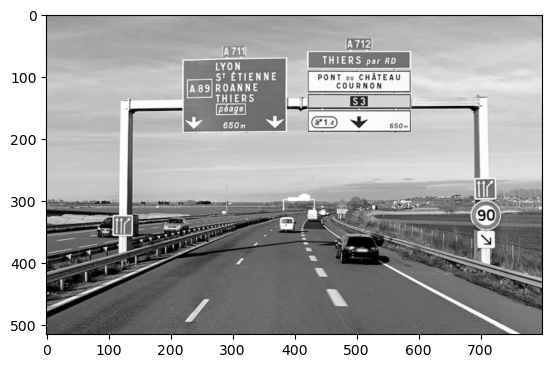

In [2]:
img = io.imread('route6.jpg')
img = clr.rgb2gray(img)
plt.imshow(img, "gray")
plt.show()

## Détection de lignes (Canny + masque + Hough)

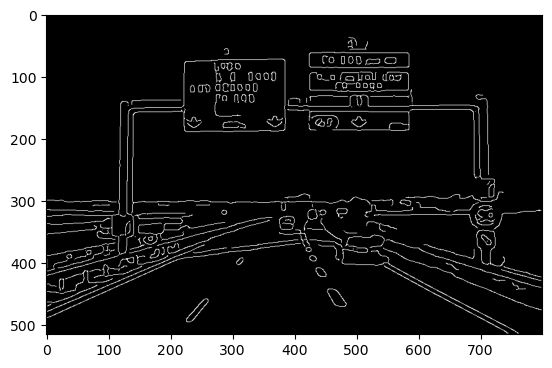

In [3]:
contours = canny(img, sigma=3)
plt.imshow(contours, "gray")
plt.show()

515 800


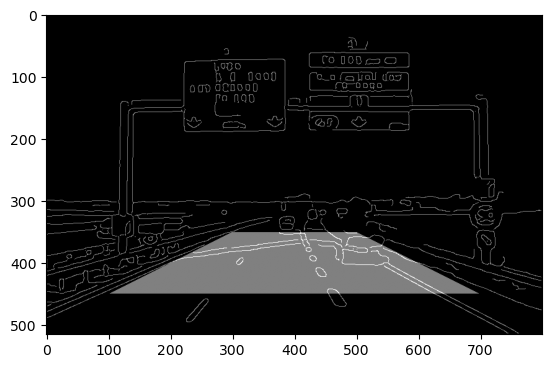

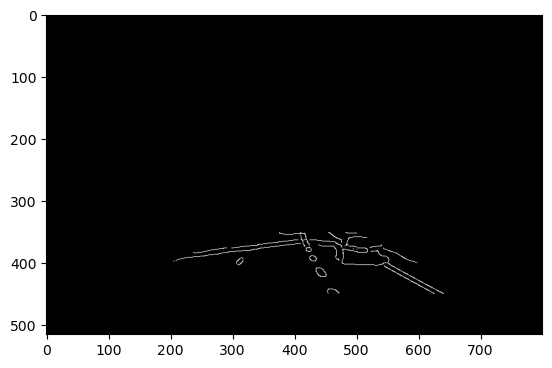

In [4]:
# Masque
R, C = contours.shape
print(R,C)
r = np.arange(R)
c = np.arange(C)
cols, rows = np.meshgrid(c, r)
mask = np.ones((R,C))
mask = np.where( rows>350, mask, 0 )
mask = np.where( rows<450, mask, 0 )
mask = np.where( rows > -.5 * cols + 500, mask, 0 )
mask = np.where( rows >  .5 * cols + 100, mask, 0 )
contours_masked = contours * mask

# Affichage
plt.figure()
plt.imshow(mask+contours, "gray")#, origin='lower')
plt.show()
# Affichage
plt.figure()
plt.imshow(contours_masked, "gray")#, origin='lower')
plt.show()

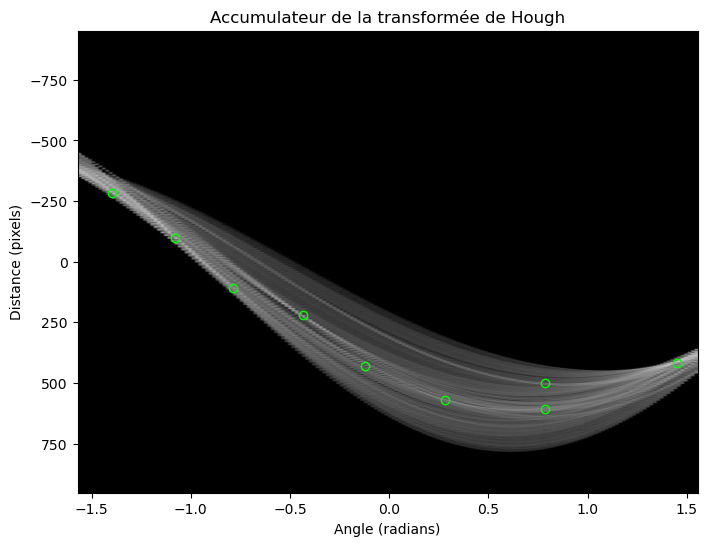

In [5]:
accumulator, angle, dist  = hough_line(contours_masked)
peaks, angles, dists = hough_line_peaks(accumulator, angle, dist,
                                        threshold=.1*accumulator.max(),
                                        min_distance = 100)

# axes = (rad2deg(angle[0]), rad2deg(angle[-1]), dist[-1], dist[0])
axes = (angle[0], angle[-1], dist[-1], dist[0])

plt.figure(figsize=(8,6))
# plt.imshow(accumulator**.5, cmap="gray", extent=axes, aspect="auto")
plt.imshow(np.log(accumulator+1), cmap="gray", extent=axes, aspect="auto")
plt.xlabel('Angle (radians)')
plt.ylabel('Distance (pixels)')
plt.title("Accumulateur de la transformée de Hough")
# plt.plot(rad2deg(angles), dists, marker='o', markeredgecolor='lime', markerfacecolor="none", linestyle="none")
plt.plot(angles, dists, marker='o', markeredgecolor='lime', markerfacecolor="none", linestyle="none")
plt.show()

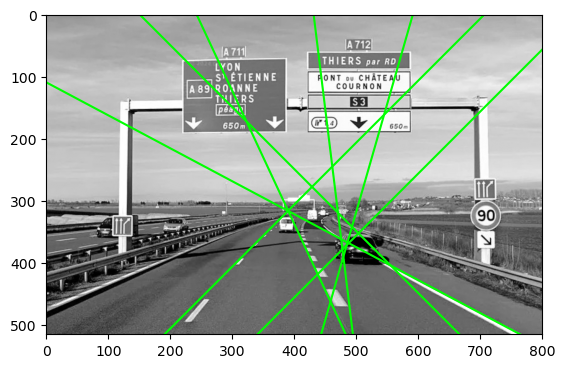

In [6]:
plt.figure
plt.imshow(img, cmap="gray")

for _, angle, dist in zip(peaks, angles, dists):

    if np.abs(angle) < .8*np.pi/2:
        
        # Coordonnée de la ligne
        x0 = 0
        y0 = dist / sin(angle)
        x1 = C
        y1 = (dist - x1*cos(angle)) / sin(angle)
        
        # Tracé de la ligne
        plt.plot((x0, x1), (y0, y1), color='lime')

plt.axis((0,C,R,0))
plt.show()

## Détection de panneaux (filtre adapté vs. SIFT)

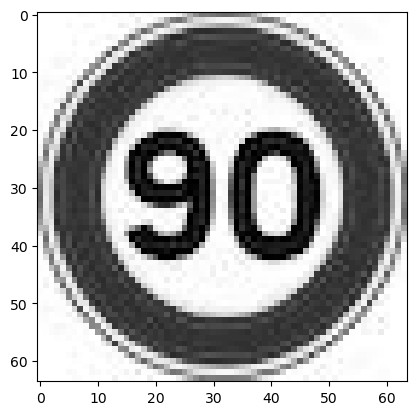

In [15]:
original_sign = io.imread("P90.png")
original_sign = clr.rgb2gray(original_sign[:,:,:3])
# resize 37
plt.imshow(original_sign, "gray")
plt.show()

30 0.36061864250711173
35 0.34060080996370323
40 0.34162003164697663
45 0.3123500558672751
50 0.4055917246730525
55 0.28530392145317357
60 0.29149801393464947

50
0.4055917246730525
0.4055917246730525


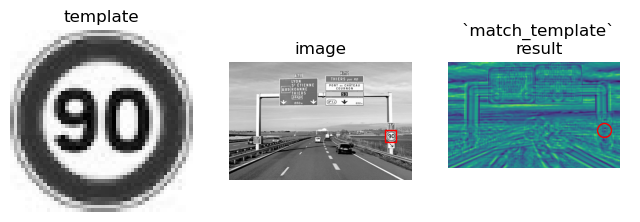

In [17]:
Smax = 0
result_max = 0
for S in range(30,65,5):

    # Supprime les matchs trop éloignés
    

    sign = resize(original_sign, (S,S))
    result = match_template(img, sign)
    print(S, np.max(result))
    if np.max(result) > result_max:
        result_max = np.max(result)
        Smax = S

print()
S = Smax
print(Smax)
print(result_max)
sign = resize(original_sign, (S,S))
result = match_template(img, sign)
print(np.max(result))
ij = np.unravel_index(np.argmax(result), result.shape)
x, y = ij[::-1]

fig = plt.figure(figsize=(8, 3))
ax1 = plt.subplot(1, 3, 1)
ax2 = plt.subplot(1, 3, 2)
ax3 = plt.subplot(1, 3, 3, sharex=ax2, sharey=ax2)

ax1.imshow(sign, cmap=plt.cm.gray)
ax1.set_axis_off()
ax1.set_title('template')

ax2.imshow(img, cmap=plt.cm.gray)
ax2.set_axis_off()
ax2.set_title('image')
# highlight matched region
hcoin, wcoin = sign.shape
rect = plt.Rectangle((x, y), wcoin, hcoin, edgecolor='r', facecolor='none')
ax2.add_patch(rect)

ax3.imshow(result)
ax3.set_axis_off()
ax3.set_title('`match_template`\nresult')
# highlight matched region
ax3.autoscale(False)
ax3.plot(x, y, 'o', markeredgecolor='r', markerfacecolor='none', markersize=10)

plt.show()

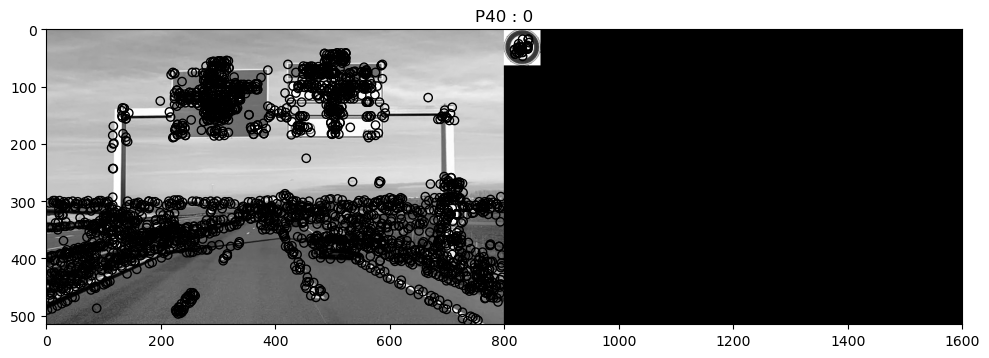

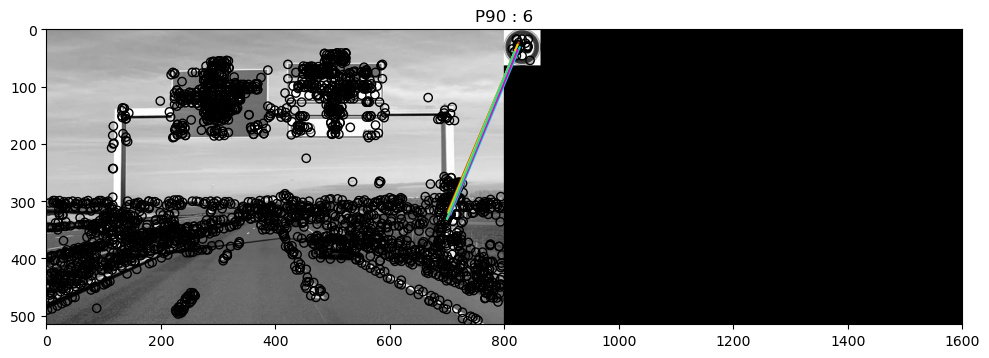

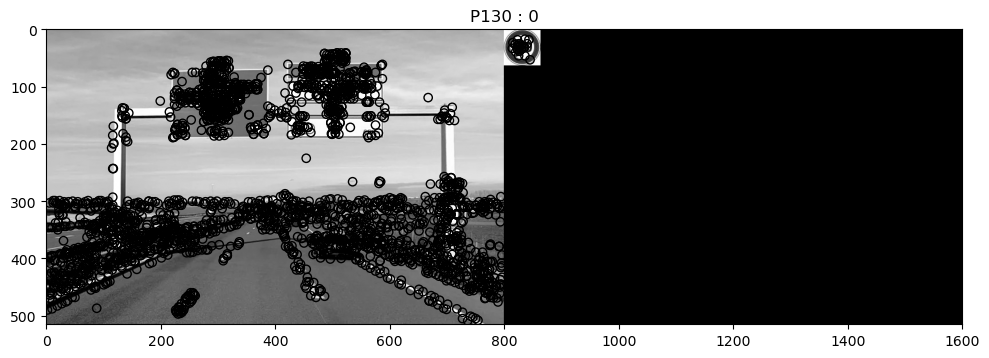

In [11]:
panels = ["P40", "P90", "P130"]

# SIFT sur l'image
descriptor_extractor = SIFT()
descriptor_extractor.detect_and_extract(img)
keypoints0 = descriptor_extractor.keypoints
descriptors0 = descriptor_extractor.descriptors

for P in panels:

    # Panneau
    sign = io.imread(f"{P}.png")
    sign = clr.rgb2gray(sign[:,:,:3])

    # SIFT sur le panneau
    descriptor_extractor.detect_and_extract(sign)
    keypoints1 = descriptor_extractor.keypoints
    descriptors1 = descriptor_extractor.descriptors

    # Matching
    matches = match_descriptors(descriptors0, descriptors1, max_ratio=.6)

    # Affichage
    plt.figure(figsize=(10, 5))
    plot_matched_features(
        img,
        sign,
        keypoints0=keypoints0,
        keypoints1=keypoints1,
        matches=matches,
        ax=plt.gca(),
    )
    plt.tight_layout()
    plt.title(f"{P} : {matches.shape[0]}")
    plt.show()